# Voice Cloning Project — Models 1, 2, 3 (50 epochs each)
### Model 1: Denoising Autoencoder (audio preprocessing)
### Model 2: Variational Autoencoder / VAE (speaker voice-identity embedding)
### Model 3: Transformer (text → acoustic features)

Dataset: **VCTK Corpus** (multi-speaker English speech), loaded via Hugging Face.

Each model trains for **50 epochs**, with **automatic checkpoint-resume**: if Colab disconnects partway through,
just re-run the same training cell — it picks up from the last saved epoch instead of starting over.

## 0. Setup — install packages

In [1]:
!pip install torch torchaudio librosa soundfile numpy matplotlib tqdm datasets -q

In [2]:
import os, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import librosa
import librosa.display
import matplotlib.pyplot as plt
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 1. Mount Google Drive
Checkpoints save here so they survive Colab session resets.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

CHECKPOINT_DIR = "/content/drive/MyDrive/voice_cloning_project/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print("Checkpoints folder:", CHECKPOINT_DIR)
print("Existing files:", os.listdir(CHECKPOINT_DIR))

Mounted at /content/drive
Checkpoints folder: /content/drive/MyDrive/voice_cloning_project/checkpoints
Existing files: ['autoencoder_full.pt', 'autoencoder.pt', 'speaker_vae.pt', 'speaker_vae_full.pt']


## 2. Download VCTK (multi-speaker corpus)

**Note:** torchaudio's built-in `VCTK_092(download=True)` fails with `HTTPError: 403 Forbidden` (Edinburgh's
server blocks scripted downloads). We use Hugging Face's mirror instead, pointed at its script-free Parquet
conversion (the raw repo uses a legacy loading script format that's no longer supported).

In [4]:
from datasets import load_dataset

vctk_dataset = load_dataset(
    "CSTR-Edinburgh/vctk",
    split="train",
    revision="refs/convert/parquet",
)
print("Total utterances in full corpus:", len(vctk_dataset))
print("Available columns:", vctk_dataset.column_names)

Resolving data files:   0%|          | 0/27 [00:00<?, ?it/s]

main/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  472MB            

main/train/0000.parquet: downloading bytes:           |  0.00B            

main/train/0001.parquet: reconstructing file:   0%|          |  0.00B /  415MB            

main/train/0001.parquet: downloading bytes:           |  0.00B            

main/train/0002.parquet: reconstructing file:   0%|          |  0.00B /  441MB            

... (48 outputs left out)

main/train/0026.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Loading dataset shards:   0%|          | 0/24 [00:00<?, ?it/s]

Total utterances in full corpus: 88156
Available columns: ['speaker_id', 'audio', 'file', 'text', 'text_id', 'age', 'gender', 'accent', 'region', 'comment']


## 3. Scope down to a manageable subset of speakers

10 speakers is plenty to learn a meaningful voice-identity space, and keeps training feasible on a free Colab GPU.

In [5]:
SELECTED_SPEAKERS = ["p225", "p226", "p227", "p228", "p229",
                      "p230", "p231", "p232", "p233", "p234"]

vctk_subset = vctk_dataset.filter(lambda ex: ex["speaker_id"] in SELECTED_SPEAKERS)
print(f"Filtered to {len(vctk_subset)} utterances across {len(SELECTED_SPEAKERS)} speakers")
assert len(vctk_subset) > 0, "No matching utterances - check speaker_id format in vctk_dataset."

HOLDOUT_SPEAKERS = SELECTED_SPEAKERS[-2:]          # unseen speakers, reserved for later zero-shot testing
TRAIN_SPEAKERS = SELECTED_SPEAKERS[:-2]

train_hf = vctk_subset.filter(lambda ex: ex["speaker_id"] in TRAIN_SPEAKERS)
holdout_hf = vctk_subset.filter(lambda ex: ex["speaker_id"] in HOLDOUT_SPEAKERS)

print(f"Train utterances: {len(train_hf)} | Held-out (unseen) utterances: {len(holdout_hf)}")

Filter:   0%|          | 0/88156 [00:00<?, ? examples/s]

Filtered to 7428 utterances across 10 speakers


Filter:   0%|          | 0/7428 [00:00<?, ? examples/s]

Filter:   0%|          | 0/7428 [00:00<?, ? examples/s]

Train utterances: 5970 | Held-out (unseen) utterances: 1458


## 4. Audio → Mel-Spectrogram utilities

In [6]:
SAMPLE_RATE = 22050
N_MELS = 80
N_FFT = 1024
HOP_LENGTH = 256
SEGMENT_FRAMES = 128

def waveform_to_mel(y, orig_sr, sr=SAMPLE_RATE, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP_LENGTH):
    y = np.array(y, dtype=np.float32)
    if orig_sr != sr:
        y = librosa.resample(y, orig_sr=orig_sr, target_sr=sr)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_norm = (mel_db + 80) / 80
    return np.clip(mel_norm, 0, 1).astype(np.float32)

def random_crop_or_pad(mel, target_frames=SEGMENT_FRAMES):
    T = mel.shape[1]
    if T >= target_frames:
        start = random.randint(0, T - target_frames)
        return mel[:, start:start + target_frames]
    return np.pad(mel, ((0, 0), (0, target_frames - T)), mode="constant")

def fixed_crop_or_pad(mel, target_frames=SEGMENT_FRAMES):
    # deterministic crop from the start - used for Model 3, since text must correspond to the audio shown
    T = mel.shape[1]
    if T >= target_frames:
        return mel[:, :target_frames]
    return np.pad(mel, ((0, 0), (0, target_frames - T)), mode="constant")

## 5. Checkpoint-resume helper
Used by all three training loops so a Colab disconnect never costs you lost progress.

In [7]:
def save_checkpoint(name, model, optimizer, epoch, loss_history, extra=None):
    state = {
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "epoch": epoch,
        "loss_history": loss_history,
        "extra": extra or {},
    }
    torch.save(state, os.path.join(CHECKPOINT_DIR, f"{name}.pt"))

def load_checkpoint_if_exists(name, model, optimizer):
    path = os.path.join(CHECKPOINT_DIR, f"{name}.pt")
    if os.path.exists(path):
        state = torch.load(path, map_location=device)
        model.load_state_dict(state["model_state"])
        optimizer.load_state_dict(state["optimizer_state"])
        print(f"Resumed '{name}' from epoch {state['epoch']} "
              f"({len(state['loss_history'])} loss points already recorded).")
        return state["epoch"], state["loss_history"], state.get("extra", {})
    print(f"No existing checkpoint for '{name}' - starting fresh.")
    return 0, [], {}

## 6. PyTorch Dataset classes (Models 1 & 2)

In [8]:
class DenoisingSpectrogramDataset(Dataset):
    """Returns (noisy_mel, clean_mel) pairs for training the Autoencoder."""
    def __init__(self, hf_subset, noise_std=0.15):
        self.data = hf_subset
        self.noise_std = noise_std

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ex = self.data[idx]
        mel = waveform_to_mel(ex["audio"]["array"], ex["audio"]["sampling_rate"])
        mel = random_crop_or_pad(mel)
        clean = torch.tensor(mel)
        noisy = torch.clamp(clean + torch.randn_like(clean) * self.noise_std, 0, 1)
        return noisy.unsqueeze(0), clean.unsqueeze(0)


SPEAKER_TO_IDX = {spk: i for i, spk in enumerate(SELECTED_SPEAKERS)}

class SpeakerSpectrogramDataset(Dataset):
    """Returns (mel, speaker_idx) pairs for training the VAE."""
    def __init__(self, hf_subset):
        self.data = hf_subset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ex = self.data[idx]
        mel = waveform_to_mel(ex["audio"]["array"], ex["audio"]["sampling_rate"])
        mel = random_crop_or_pad(mel)
        return torch.tensor(mel).unsqueeze(0), SPEAKER_TO_IDX[ex["speaker_id"]]


BATCH_SIZE = 16
train_ds_ae = DenoisingSpectrogramDataset(train_hf)
train_loader_ae = DataLoader(train_ds_ae, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

train_ds_vae = SpeakerSpectrogramDataset(train_hf)
train_loader_vae = DataLoader(train_ds_vae, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

---
## MODEL 1: Denoising Autoencoder

**Job:** clean up noisy/corrupted spectrograms before they're used downstream.

In [9]:
class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 3, 2, 1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, 2, 1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, 2, 1, output_padding=1), nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

In [10]:
# --- Training setup (Model 1) ---
EPOCHS_AE = 50
LR_AE = 1e-3

autoencoder = DenoisingAutoencoder().to(device)
optimizer_ae = torch.optim.Adam(autoencoder.parameters(), lr=LR_AE)
criterion_ae = nn.MSELoss()

start_epoch, ae_losses, _ = load_checkpoint_if_exists("autoencoder_full", autoencoder, optimizer_ae)

for epoch in range(start_epoch, EPOCHS_AE):
    autoencoder.train()
    epoch_loss = 0.0
    for noisy, clean in tqdm(train_loader_ae, desc=f"AE Epoch {epoch+1}/{EPOCHS_AE}"):
        noisy, clean = noisy.to(device), clean.to(device)
        optimizer_ae.zero_grad()
        recon = autoencoder(noisy)
        loss = criterion_ae(recon, clean)
        loss.backward()
        optimizer_ae.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader_ae)
    ae_losses.append(avg_loss)
    print(f"Epoch {epoch+1}: reconstruction MSE = {avg_loss:.4f}")
    save_checkpoint("autoencoder_full", autoencoder, optimizer_ae, epoch + 1, ae_losses)

# Also save under the plain filename other notebooks/checkpoints expect
torch.save(autoencoder.state_dict(), os.path.join(CHECKPOINT_DIR, "autoencoder.pt"))
print("Model 1 (Autoencoder) training complete.")

Resumed 'autoencoder_full' from epoch 50 (50 loss points already recorded).
Model 1 (Autoencoder) training complete.


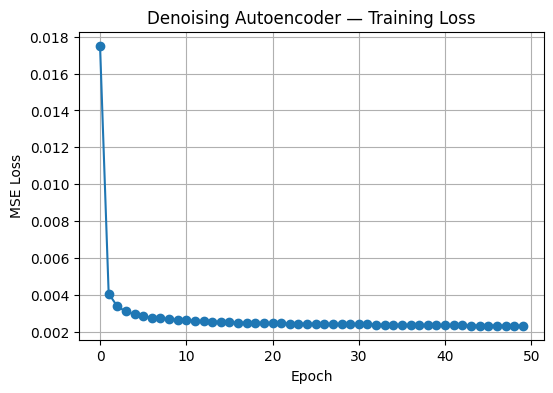

In [11]:
plt.figure(figsize=(6,4))
plt.plot(ae_losses, marker='o')
plt.title("Denoising Autoencoder — Training Loss")
plt.xlabel("Epoch"); plt.ylabel("MSE Loss"); plt.grid(True)
plt.show()

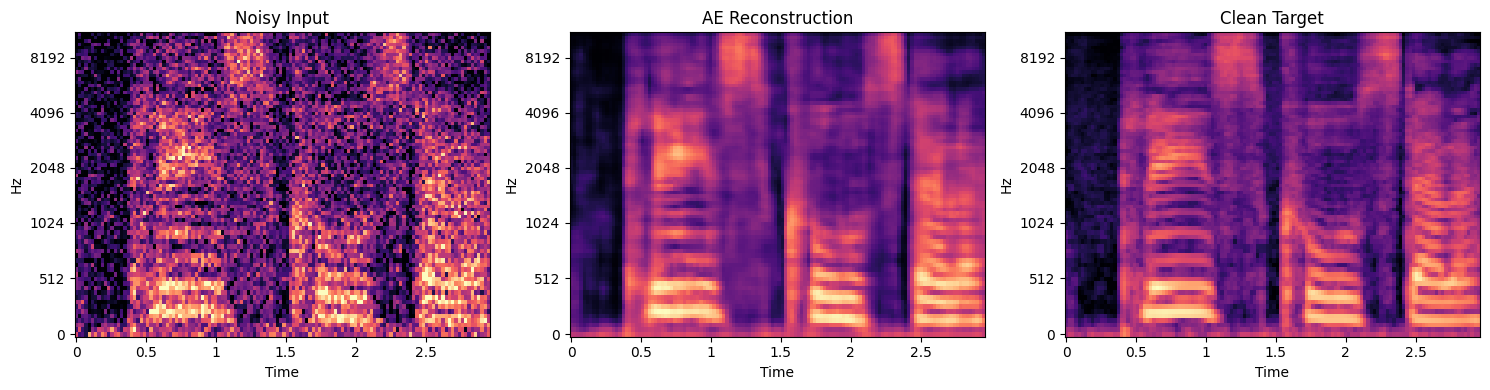

In [12]:
# --- Visualize: noisy input vs reconstructed vs clean target ---
autoencoder.eval()
noisy_sample, clean_sample = train_ds_ae[0]
with torch.no_grad():
    recon_sample = autoencoder(noisy_sample.unsqueeze(0).to(device)).cpu().squeeze()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(axes,
                           [noisy_sample.squeeze(), recon_sample, clean_sample.squeeze()],
                           ["Noisy Input", "AE Reconstruction", "Clean Target"]):
    librosa.display.specshow(data.numpy(), ax=ax, x_axis='time', y_axis='mel', sr=SAMPLE_RATE)
    ax.set_title(title)
plt.tight_layout()
plt.show()

---
## MODEL 2: VAE — Speaker Voice-Identity Embedding

**Job:** learn a compact latent vector per utterance capturing *who* is speaking, so later stages can
condition generation on a target speaker.

In [13]:
LATENT_DIM = 64
NUM_SPEAKERS = len(SELECTED_SPEAKERS)

class SpeakerVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_speakers=NUM_SPEAKERS):
        super().__init__()
        self.enc_conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
        )
        self.flatten_dim = 64 * 10 * 16
        self.fc_mu = nn.Linear(self.flatten_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_dim, latent_dim)
        self.fc_dec = nn.Linear(latent_dim, self.flatten_dim)
        self.dec_conv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 3, 2, 1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, 2, 1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, 2, 1, output_padding=1), nn.Sigmoid(),
        )
        self.speaker_classifier = nn.Linear(latent_dim, num_speakers)

    def encode(self, x):
        h = self.enc_conv(x)
        h = h.view(h.size(0), -1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def decode(self, z):
        h = self.fc_dec(z)
        h = h.view(-1, 64, 10, 16)
        return self.dec_conv(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar, self.speaker_classifier(z)

In [14]:
def vae_loss(recon, target, mu, logvar, speaker_logits, speaker_labels,
             kl_weight=0.001, speaker_weight=0.5):
    recon_loss = F.mse_loss(recon, target, reduction='mean')
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    speaker_loss = F.cross_entropy(speaker_logits, speaker_labels)
    total = recon_loss + kl_weight * kl_loss + speaker_weight * speaker_loss
    return total, recon_loss, kl_loss, speaker_loss

In [15]:
# --- Training setup (Model 2) ---
EPOCHS_VAE = 50
LR_VAE = 1e-3

speaker_vae = SpeakerVAE().to(device)
optimizer_vae = torch.optim.Adam(speaker_vae.parameters(), lr=LR_VAE)

start_epoch, vae_losses, _ = load_checkpoint_if_exists("speaker_vae_full", speaker_vae, optimizer_vae)

for epoch in range(start_epoch, EPOCHS_VAE):
    speaker_vae.train()
    epoch_loss, epoch_recon, epoch_kl, epoch_spk = 0.0, 0.0, 0.0, 0.0
    for mel, spk_idx in tqdm(train_loader_vae, desc=f"VAE Epoch {epoch+1}/{EPOCHS_VAE}"):
        mel, spk_idx = mel.to(device), spk_idx.to(device)
        optimizer_vae.zero_grad()
        recon, mu, logvar, speaker_logits = speaker_vae(mel)
        loss, r_loss, k_loss, s_loss = vae_loss(recon, mel, mu, logvar, speaker_logits, spk_idx)
        loss.backward()
        optimizer_vae.step()
        epoch_loss += loss.item(); epoch_recon += r_loss.item()
        epoch_kl += k_loss.item(); epoch_spk += s_loss.item()

    n = len(train_loader_vae)
    vae_losses.append(epoch_loss / n)
    print(f"Epoch {epoch+1}: total={epoch_loss/n:.4f}  recon={epoch_recon/n:.4f}  "
          f"kl={epoch_kl/n:.4f}  speaker_ce={epoch_spk/n:.4f}")
    save_checkpoint("speaker_vae_full", speaker_vae, optimizer_vae, epoch + 1, vae_losses)

torch.save(speaker_vae.state_dict(), os.path.join(CHECKPOINT_DIR, "speaker_vae.pt"))
print("Model 2 (Speaker VAE) training complete.")

Resumed 'speaker_vae_full' from epoch 50 (50 loss points already recorded).
Model 2 (Speaker VAE) training complete.


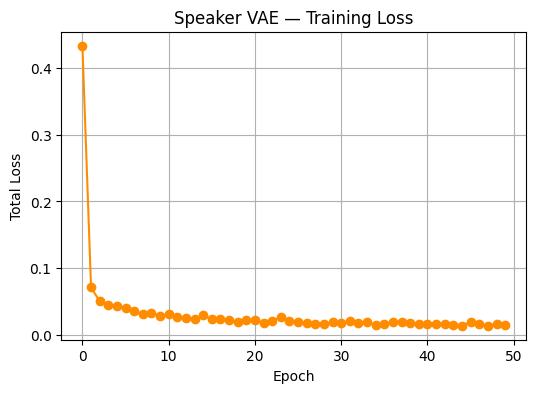

In [16]:
plt.figure(figsize=(6,4))
plt.plot(vae_losses, marker='o', color='darkorange')
plt.title("Speaker VAE — Training Loss")
plt.xlabel("Epoch"); plt.ylabel("Total Loss"); plt.grid(True)
plt.show()

Unique speakers represented: [0 1 2 3 4 5 6 7]


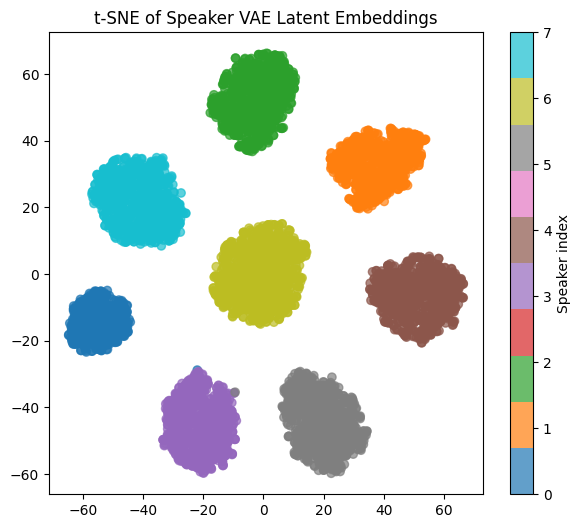

In [17]:
from sklearn.manifold import TSNE

speaker_vae.eval()
all_z, all_labels = [], []
eval_loader = DataLoader(train_ds_vae, batch_size=32, shuffle=False)
with torch.no_grad():
    for mel, spk_idx in eval_loader:
        mu, _ = speaker_vae.encode(mel.to(device))
        all_z.append(mu.cpu().numpy())
        all_labels.append(spk_idx.numpy())

all_z = np.concatenate(all_z, axis=0)
all_labels = np.concatenate(all_labels, axis=0)
print("Unique speakers represented:", np.unique(all_labels))

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
z_2d = tsne.fit_transform(all_z)

plt.figure(figsize=(7, 6))
scatter = plt.scatter(z_2d[:, 0], z_2d[:, 1], c=all_labels, cmap='tab10', alpha=0.7)
plt.title("t-SNE of Speaker VAE Latent Embeddings")
plt.colorbar(scatter, ticks=range(len(SELECTED_SPEAKERS)), label="Speaker index")
plt.show()

---
## Text preprocessing for Model 3 (character-level tokenizer)

VCTK utterances are short single sentences, so a simple character-level tokenizer is enough — no separate
phoneme dictionary/tool needed.

In [18]:
MAX_TEXT_LEN = 60

def get_text_field(ex):
    for key in ["text", "transcription", "sentence", "normalized_text"]:
        if key in ex and ex[key]:
            return ex[key]
    raise KeyError("Could not find a text field - check vctk_subset.column_names")

all_text = [get_text_field(ex) for ex in train_hf]
chars = sorted(set("".join(all_text).lower()))
PAD_ID, UNK_ID = 0, 1
char2id = {c: i + 2 for i, c in enumerate(chars)}
VOCAB_SIZE = len(char2id) + 2

def encode_text(text, max_len=MAX_TEXT_LEN):
    ids = [char2id.get(c, UNK_ID) for c in text.lower()][:max_len]
    mask = [1] * len(ids) + [0] * (max_len - len(ids))
    ids = ids + [PAD_ID] * (max_len - len(ids))
    return np.array(ids, dtype=np.int64), np.array(mask, dtype=np.float32)

print("Vocab size:", VOCAB_SIZE)

Vocab size: 35


## Dataset class for Model 3 (text + target mel)

In [19]:
class TTSDataset(Dataset):
    def __init__(self, hf_subset):
        self.data = hf_subset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ex = self.data[idx]
        text_ids, text_mask = encode_text(get_text_field(ex))
        mel = waveform_to_mel(ex["audio"]["array"], ex["audio"]["sampling_rate"])
        mel = fixed_crop_or_pad(mel)
        return torch.tensor(text_ids), torch.tensor(text_mask), torch.tensor(mel).unsqueeze(0)

tts_train_ds = TTSDataset(train_hf)
tts_train_loader = DataLoader(tts_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
print("TTS training batches per epoch:", len(tts_train_loader))

TTS training batches per epoch: 374


---
## MODEL 3: Transformer — Text → Acoustic Features

**Design (simplified, course-project scale):**
- A Transformer **encoder** processes the input text (character embeddings + positional encoding).
- A set of **learned fixed-length query vectors** (128, matching the mel segment length) attend to the text
  encoding via a Transformer **decoder** (cross-attention) — this avoids needing an external forced-aligner.
- **Speaker identity** comes from running the target utterance's own mel through the just-trained Model 2 (VAE)
  encoder — a *reference encoder* approach. At inference, you'd swap in any reference clip from the target
  speaker instead.
- Output: a predicted mel-spectrogram, trained with L1 loss against the real one.

In [20]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=256):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class TransformerTTS(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, d_model=256, nhead=4,
                 enc_layers=3, dec_layers=3, n_mels=N_MELS, seg_frames=SEGMENT_FRAMES,
                 speaker_dim=LATENT_DIM):
        super().__init__()
        self.text_embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.pos_enc = PositionalEncoding(d_model)

        enc_layer = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=512, batch_first=True)
        self.text_encoder = nn.TransformerEncoder(enc_layer, num_layers=enc_layers)

        self.mel_queries = nn.Parameter(torch.randn(seg_frames, d_model) * 0.02)
        dec_layer = nn.TransformerDecoderLayer(d_model, nhead, dim_feedforward=512, batch_first=True)
        self.mel_decoder = nn.TransformerDecoder(dec_layer, num_layers=dec_layers)

        self.speaker_proj = nn.Linear(speaker_dim, d_model)
        self.output_proj = nn.Linear(d_model, n_mels)

    def forward(self, text_ids, text_mask, speaker_emb):
        B = text_ids.size(0)
        text_emb = self.pos_enc(self.text_embed(text_ids))
        key_padding_mask = (text_mask == 0)
        enc_out = self.text_encoder(text_emb, src_key_padding_mask=key_padding_mask)

        spk = self.speaker_proj(speaker_emb).unsqueeze(1)
        enc_out = enc_out + spk

        queries = self.mel_queries.unsqueeze(0).expand(B, -1, -1)
        dec_out = self.mel_decoder(tgt=queries, memory=enc_out, memory_key_padding_mask=key_padding_mask)

        mel_out = self.output_proj(dec_out)
        mel_out = torch.sigmoid(mel_out).transpose(1, 2).unsqueeze(1)
        return mel_out

In [21]:
# --- Training setup (Model 3) ---
EPOCHS_TRANSFORMER = 50
LR_TRANSFORMER = 3e-4

transformer_tts = TransformerTTS().to(device)
optimizer_tr = torch.optim.Adam(transformer_tts.parameters(), lr=LR_TRANSFORMER)

# Speaker VAE stays frozen from here on - it already finished training above
speaker_vae.eval()
for p in speaker_vae.parameters():
    p.requires_grad = False

start_epoch, tr_losses, _ = load_checkpoint_if_exists("transformer", transformer_tts, optimizer_tr)

for epoch in range(start_epoch, EPOCHS_TRANSFORMER):
    transformer_tts.train()
    epoch_loss = 0.0
    for text_ids, text_mask, mel_target in tqdm(tts_train_loader, desc=f"Transformer Epoch {epoch+1}/{EPOCHS_TRANSFORMER}"):
        text_ids, text_mask, mel_target = text_ids.to(device), text_mask.to(device), mel_target.to(device)

        with torch.no_grad():
            spk_mu, _ = speaker_vae.encode(mel_target)

        optimizer_tr.zero_grad()
        pred_mel = transformer_tts(text_ids, text_mask, spk_mu)
        loss = F.l1_loss(pred_mel, mel_target)
        loss.backward()
        optimizer_tr.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(tts_train_loader)
    tr_losses.append(avg_loss)
    print(f"Epoch {epoch+1}: L1 mel loss = {avg_loss:.4f}")
    save_checkpoint("transformer", transformer_tts, optimizer_tr, epoch + 1, tr_losses)

torch.save(transformer_tts.state_dict(), os.path.join(CHECKPOINT_DIR, "transformer.pt"))
print("Model 3 (Transformer) training complete.")

No existing checkpoint for 'transformer' - starting fresh.


Transformer Epoch 1/50: 100%|██████████| 374/374 [02:40<00:00,  2.33it/s]


Epoch 1: L1 mel loss = 0.1061


Transformer Epoch 2/50: 100%|██████████| 374/374 [02:35<00:00,  2.41it/s]


Epoch 2: L1 mel loss = 0.0738


Transformer Epoch 3/50: 100%|██████████| 374/374 [02:34<00:00,  2.43it/s]


... (91 outputs left out)

Transformer Epoch 49/50: 100%|██████████| 374/374 [02:29<00:00,  2.50it/s]


Epoch 49: L1 mel loss = 0.0406


Transformer Epoch 50/50: 100%|██████████| 374/374 [02:34<00:00,  2.43it/s]


Epoch 50: L1 mel loss = 0.0405
Model 3 (Transformer) training complete.


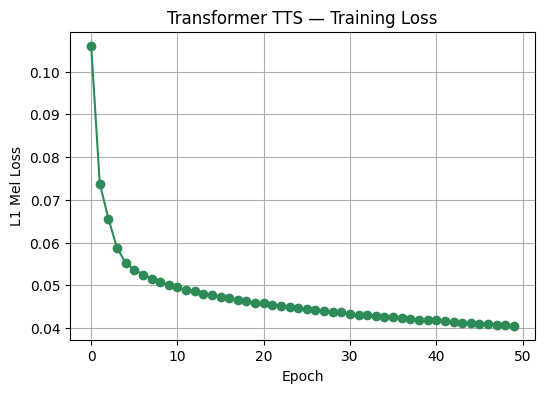

In [22]:
plt.figure(figsize=(6,4))
plt.plot(tr_losses, marker='o', color='seagreen')
plt.title("Transformer TTS — Training Loss")
plt.xlabel("Epoch"); plt.ylabel("L1 Mel Loss"); plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


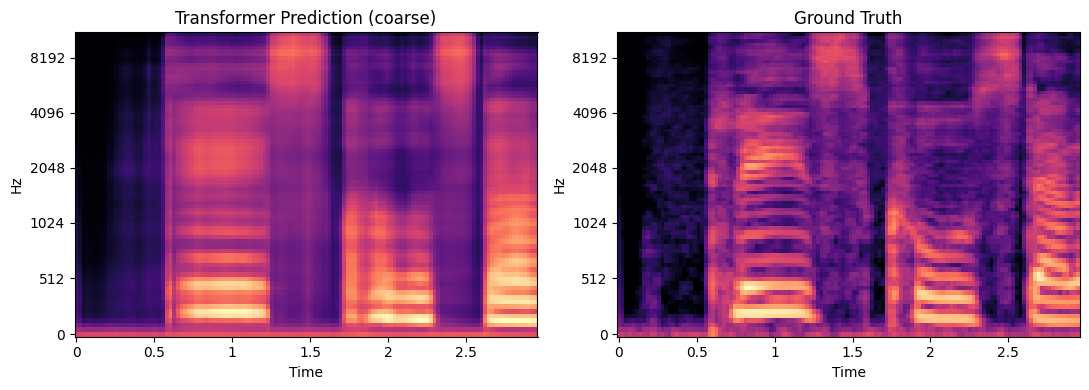

In [23]:
# --- Visualize: predicted (coarse) mel vs ground truth ---
transformer_tts.eval()
sample_text_ids, sample_text_mask, sample_mel = tts_train_ds[0]
sample_text_ids = sample_text_ids.unsqueeze(0).to(device)
sample_text_mask = sample_text_mask.unsqueeze(0).to(device)
sample_mel_gpu = sample_mel.unsqueeze(0).to(device)

with torch.no_grad():
    spk_mu, _ = speaker_vae.encode(sample_mel_gpu)
    pred_mel = transformer_tts(sample_text_ids, sample_text_mask, spk_mu).cpu().squeeze()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, title in zip(axes, [pred_mel, sample_mel.squeeze()],
                           ["Transformer Prediction (coarse)", "Ground Truth"]):
    librosa.display.specshow(data.numpy(), ax=ax, x_axis='time', y_axis='mel', sr=SAMPLE_RATE)
    ax.set_title(title)
plt.tight_layout()
plt.show()

---
## Summary — what you now have

| # | Model | Epochs | Checkpoint saved to Drive |
|---|---|---|---|
| 1 | Denoising Autoencoder | 50 | `autoencoder.pt` (+ `autoencoder_full.pt` with full resume state) |
| 2 | Speaker VAE | 50 | `speaker_vae.pt` (+ `speaker_vae_full.pt` with full resume state) |
| 3 | Transformer | 50 | `transformer.pt` |

**Checkpoint-resume:** every training loop above checks Drive for an existing checkpoint first and resumes from
the last completed epoch — if Colab disconnects mid-training, just re-run the same cell rather than restarting.

**Next models (not in this notebook):** Diffusion (prosody refinement) and GAN vocoder (waveform synthesis) —
come back once you're ready to continue the pipeline.